<img src="logo.png" alt="Vegeta" width="240">

# Svarog-industrial — a 1 kW fibre laser for welding metal

This is what the Svarog series was for. The fibre MOPA of notebook 47 scaled to a kilowatt at the workpiece on Hyperion's
`fibre` module — a 30/250 Yb power stage seeded by 47's amplifier and counter-pumped by six 976 nm modules through a
combiner — its heat budget (the active fibre on a cooled spool, the cladding-mode stripper, the process fibre, the head's
lenses), the 20 m process fibre and the welding head on `welding` (beam parameter product, spot, cone, depth of focus), and
the welds it makes in mild steel and aluminium: the keyhole threshold, penetration against speed, the process window per
thickness. The device as numbers is `designs/svarog_industrial.py` (`import svarog_industrial as si`); the physics and the
solvers are [docs/svarog_physics.md](../docs/svarog_physics.md) and [docs/svarog_solvers.md](../docs/svarog_solvers.md).
Notebook 47's report is read for the seed (its amplifier's output); without it the seed is the recorded 59 W.

No structural analysis: the laser is a coil on a water-cooled spool, a combiner, a stripper and a catalogue welding head —
nothing load-bearing worth an FEA; the enclosure is sheet metal and its *optical* duty is notebook 49's. The record goes to
`designs/data/svarog_industrial_design.json` and `designs/data/reports/48_svarog_weld.json`.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import fibre as fb, welding as wd, thermal as th
import svarog_industrial as si, svarog_industrial_drawings as sid, svarog_fiber_drawings as sfd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
OUT = Path("output/48_svarog_weld"); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path("designs/data")
from vegeta import yanus
GATE = yanus.enter("48_svarog_weld", debug=DEBUG)    # needs vegeta.hyperion; takes 47's report (optional); gives the design and the report
R47_PATH = DATA / "reports" / "47_svarog_fiber.json"
R47 = json.loads(R47_PATH.read_text()) if R47_PATH.exists() else None
SEED = R47["amplifier"]["counter"]["output_W"] if R47 else si.SEED_DEFAULT
print(f"seed from notebook 47: {SEED:.1f} W" if R47 else f"WARNING: 47's report missing — seed taken as {SEED:g} W")

seed from notebook 47: 58.9 W


## 1. The power stage

A 30/250 µm Yb double-clad fibre (core NA 0.06, V = 5.3: few-mode, coiled to keep LP₀₁) doped to its datasheet's 2 dB/m
at 976 nm, counter-pumped by six wavelength-stabilised 220 W modules through a (6+1)×1 combiner — the pigtails' étendue
must fit the 250 µm, NA 0.46 cladding. The length by the same rule as notebook 47 (the shortest within 3 % of the best),
then the pump that puts exactly 1 kW out, and the power evolution along the fibre.

30/250 Yb double-clad: V 5.28, MFD 23.5 µm, Γ_p 0.0144; pumps: 6 × 220 W → 1254 W launched at most; étendue: 6 ports fit, 6 used


length: best 20 m, chosen 10 m (shortest within 3% of the best); pump for 1000 W: 1077 W of 1254 W  [11 s]


output_W           1000.000
pump_W             1077.032
absorbed_W         1048.473
unabsorbed_W         28.559
gain_db              12.300
efficiency            0.928
heat_W              105.215
peak_heat_per_m      37.567
inversion_max         0.124
inversion_min         0.076
Name: power stage at 1077 W pump, dtype: float64

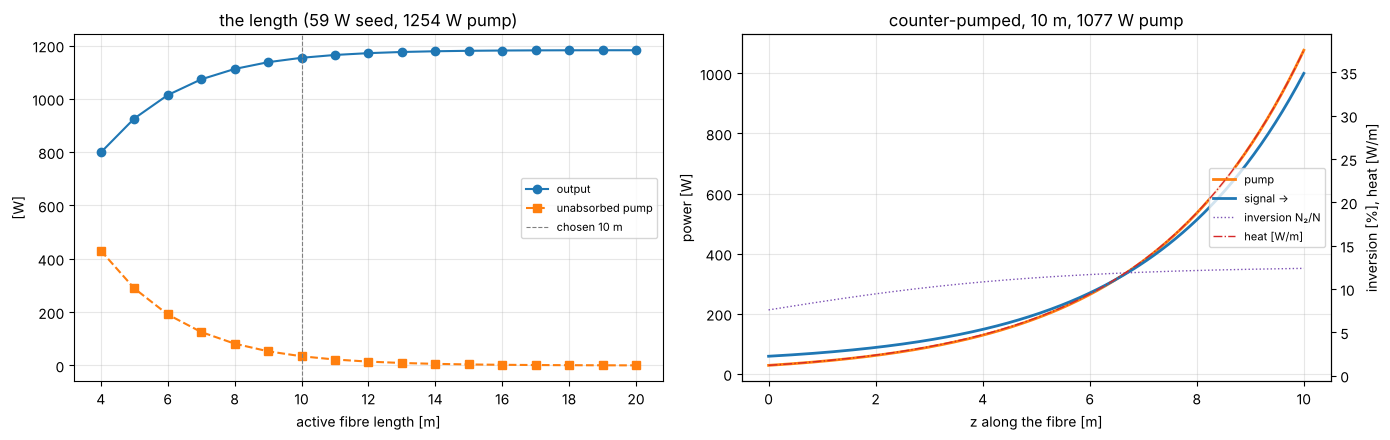

In [3]:
fit = si.PUMP_POWER.fits_the_cladding(si.FIBRE_POWER)
print(f"{si.FIBRE_POWER.name}: V {si.FIBRE_POWER.V(si.LAM):.2f}, MFD {2 * si.FIBRE_POWER.mode_radius(si.LAM) * 1e6:.1f} µm, Γ_p {si.FIBRE_POWER.overlap_clad:.4f}; "
      f"pumps: {si.PUMP_POWER.n_modules} × {si.PUMP_POWER.module_W:g} W → {si.PUMP_POWER.launched_max:.0f} W launched at most; étendue: {fit['ports_that_fit']} ports fit, {fit['used']} used")
t0 = time.time()
LC = si.power_stage_length_choice(SEED, si.PUMP_POWER.launched_max, n=si.N_SWEEP)
LEN = LC["chosen_length"]
PUMP = si.pump_for_target(LEN, SEED, n=si.N_SWEEP)
SOL = si.power_stage(LEN).solve(SEED, PUMP, n=si.N_FINE)
print(f"length: best {LC['best_length']:g} m, chosen {LEN:g} m ({LC['rule']}); pump for {si.POWER_TARGET:.0f} W: {PUMP:.0f} W of {si.PUMP_POWER.launched_max:.0f} W  [{time.time() - t0:.0f} s]")
display(pd.Series(SOL.to_dict(), name=f"power stage at {PUMP:.0f} W pump").drop("note").astype(float).round(3))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
sfd.length_view(LC, ax=axs[0], title=f"the length ({SEED:.0f} W seed, {si.PUMP_POWER.launched_max:.0f} W pump)")
sfd.evolution_view(SOL, ax=axs[1], title=f"counter-pumped, {LEN:g} m, {PUMP:.0f} W pump")
plt.tight_layout(); plt.savefig(OUT / "power_stage.png", dpi=110); plt.show()

## 2. The heat budget

Where the watts go: the pump's quantum defect becomes heat along the active fibre (the solver's integral), peaking at the
pump end — the core's rise for a water-cooled spool, a cooled plate and still air says which it must be; the unabsorbed
pump and the splice losses go into a cladding-mode stripper; the process fibre loses 0.3 dB; each lens of the head absorbs
a fraction of a per cent, estimated as a steady Gaussian rise in BK7. Conduction bookkeeping, no FEA — the parts are
catalogue parts whose cooling is specified by these numbers.

In [4]:
BUD = si.thermal_budget(SOL, LEN)
display(pd.Series({"heat in the active fibre [W]": BUD["active_fibre_heat_W"], "peak [W/m]": BUD["active_fibre_peak_W_per_m"],
                   **{f"core rise, {k} [K]": v for k, v in BUD["core_dT_per_cooling"].items()},
                   "into the cladding-mode stripper [W]": BUD["stripper_W"], "process fibre loss [W]": BUD["delivery_loss_W"], "delivered to the head [W]": BUD["delivered_W"],
                   "absorbed per lens [W]": BUD["lens_absorbed_W_each"], "lens centre rise [K]": BUD["lens_centre_dT"],
                   "coil radius for ≤ 0.05 dB [mm]": si.sf.coil_radius_for(si.FIBRE_POWER, LEN) * 1e3}, name="thermal budget").round(2))
LIM = si.sf.limits(si.FIBRE_POWER, LEN, SOL, SOL.output_W)
print(f"SRS threshold in the active fibre {LIM['srs']['P_threshold_W']:.0f} W ({LIM['srs_margin']:.1f}× the output)")

heat in the active fibre [W]                   105.21
peak [W/m]                                      37.57
core rise, water-cooled spool (h 2000) [K]      40.35
core rise, cooled plate (h 500) [K]             85.19
core rise, still air (h 10) [K]               3014.90
into the cladding-mode stripper [W]             51.32
process fibre loss [W]                          66.75
delivered to the head [W]                      933.25
absorbed per lens [W]                            1.87
lens centre rise [K]                            55.70
coil radius for ≤ 0.05 dB [mm]                  49.50
Name: thermal budget, dtype: float64

SRS threshold in the active fibre 7021 W (7.0× the output)


## 3. The delivery and the head

A 50 µm, NA 0.12 process fibre carries the beam 20 m to the head: its beam parameter product r·NA = 3 mm·mrad is the
invariant (M² ≈ 9), and the 100 mm collimator / 200 mm focusing lens image the core to a 100 µm spot with a 60 mrad cone
and a 0.8 mm Rayleigh length. SRS in the process fibre at a kilowatt is checked; the collimated beam's radius (12 mm) is the
number the guard study needs.

In [5]:
HN = si.head_numbers(BUD["delivered_W"])
display(pd.Series({"BPP [mm·mrad]": HN["bpp_mm_mrad"], "M²": HN["m2"], "collimated radius [mm]": HN["collimated_radius"] * 1e3, "spot radius [µm]": HN["spot_radius"] * 1e6,
                   "cone half-angle [mrad]": HN["cone_half_angle"] * 1e3, "Rayleigh length [mm]": HN["rayleigh_length"] * 1e3,
                   "mean irradiance at the spot [MW/cm²]": HN["mean_irradiance_W_per_cm2"] / 1e6, "SRS threshold, process fibre [kW]": HN["srs_delivery"]["P_threshold_W"] / 1e3},
                  name="delivery and head").round(3))

BPP [mm·mrad]                            3.000
M²                                       8.808
collimated radius [mm]                  12.000
spot radius [µm]                        50.000
cone half-angle [mrad]                  60.000
Rayleigh length [mm]                     0.833
mean irradiance at the spot [MW/cm²]    11.883
SRS threshold, process fibre [kW]        7.256
Name: delivery and head, dtype: float64

## 4. The welds

Mild steel and aluminium at the delivered power: the keyhole threshold at this spot (the power at which the surface
boils under a Gaussian spot in steady conduction — the textbook's ~1 MW/cm² for steel, ten times that for aluminium, which
is why aluminium needs the kilowatt), the penetration against speed from the energy balance with Swift-Hook & Gick's
melting efficiency, and the process window: the fastest full-penetration speed per thickness and the speed with 20 % of
depth in hand. Numbers to draw a weld trial around, ±40 %.

mild steel: keyhole threshold 37 W (0.48 MW/cm²); conduction pool at 300 W absorbed, 0.6 m/min: 0.52 mm wide, 0.26 mm deep
aluminium: keyhole threshold 512 W (6.52 MW/cm²); conduction pool at 300 W absorbed, 0.6 m/min: 0.09 mm wide, 0.04 mm deep


,0.3 m/min,0.5 m/min,0.75 m/min,1 m/min,1.5 m/min,2 m/min,3 m/min,4 m/min,6 m/min,8 m/min,10 m/min
mild steel,4.46,3.38,2.70,2.29,1.82,1.53,1.20,1.01,0.78,0.65,0.56
aluminium,3.79,2.91,2.36,2.03,1.64,1.41,1.13,0.97,0.77,0.66,0.58


thickness [mm]  v full [m/min]  v with margin [m/min]  heat input [J/mm]  feasible
mild steel 0             1.0            4.06                   3.02              18.57      True
           1             2.0            1.27                   0.92              60.74      True
           2             3.0            0.62                   0.44             125.97      True
           3             4.0            0.37                   0.26             214.19      True
           4             6.0            0.17                   0.12             459.51      True
aluminium  0             1.0            3.76                   2.69              20.84      True
           1             2.0            1.03                   0.73              77.22      True
           2             3.0            0.47                   0.33             169.04      True
           3             4.0            0.27                   0.19             296.27      True

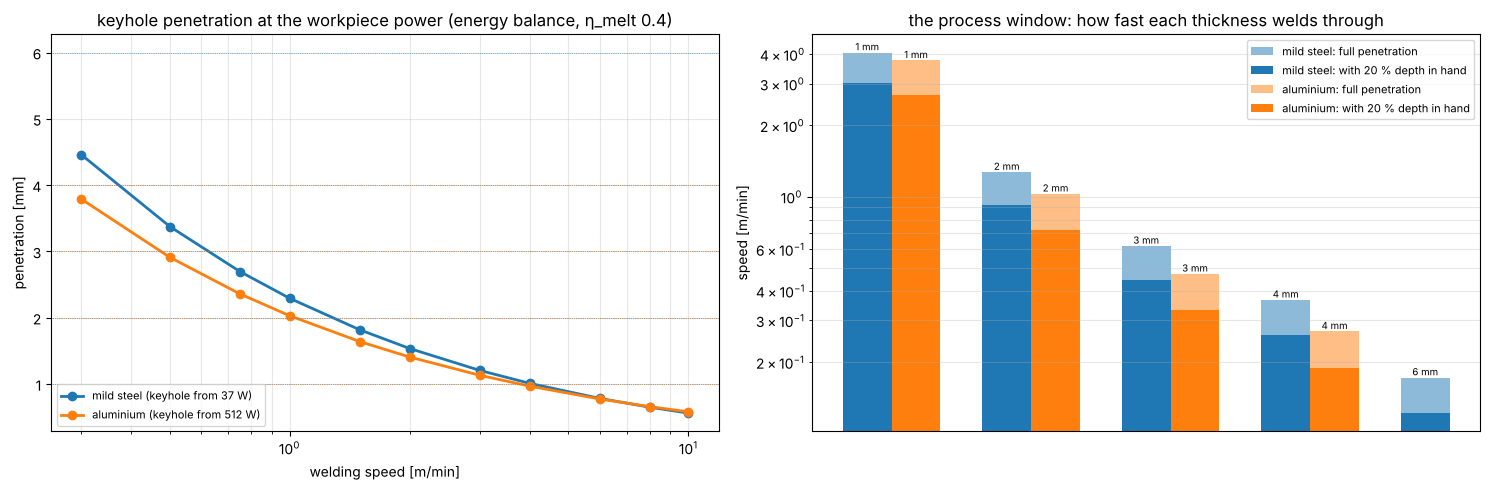

In [6]:
WELD = si.welds(BUD["delivered_W"])
for name, w in WELD.items():
    print(f"{name}: keyhole threshold {w['keyhole']['P_threshold_W']:.0f} W ({w['keyhole']['I_threshold_W_per_cm2'] / 1e6:.2f} MW/cm²); conduction pool at 300 W absorbed, 0.6 m/min: "
          f"{w['conduction_pool_300W']['width'] * 1e3:.2f} mm wide, {w['conduction_pool_300W']['depth'] * 1e3:.2f} mm deep")
PEN = pd.DataFrame({name: dict(zip([f"{v * 60:g} m/min" for v in si.SPEEDS], (w["curve"]["depth"] * 1e3).round(2))) for name, w in WELD.items()}); display(PEN.T)
WIN = pd.concat({name: pd.DataFrame(w["window"]).assign(**{"thickness [mm]": lambda d: d["thickness"] * 1e3, "v full [m/min]": lambda d: d["v_full_penetration"] * 60,
                                                              "v with margin [m/min]": lambda d: d["v_with_margin"] * 60, "heat input [J/mm]": lambda d: d["heat_input_J_per_m"] / 1e3})
                 [["thickness [mm]", "v full [m/min]", "v with margin [m/min]", "heat input [J/mm]", "feasible"]] for name, w in WELD.items()}); display(WIN.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sid.penetration_view(WELD, {n: [t * 1e3 for t in m["thicknesses"]] for n, m in si.WELD_MATERIALS.items()}, ax=axs[0])
sid.window_view(WELD, ax=axs[1])
plt.tight_layout(); plt.savefig(OUT / "welds.png", dpi=110); plt.show()

## 5. The record

In [7]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REC = si.design_record(LEN, SEED, PUMP, SOL, BUD, WELD, {"beams": si.stray_beams(BUD["delivered_W"]), "rows": []})
hy.save_design(DATA / "svarog_industrial_design.json", REC, notes=f"Svarog-industrial: {LEN:g} m power stage, {PUMP:.0f} W pump, {SOL.output_W:.0f} W out (notebook 48)")
REPORT = {"meta": {"notebook": "48_svarog_weld", "seed_W": SEED, "pump_W": PUMP, "length": LEN, "delivered_W": BUD["delivered_W"], "debug": DEBUG, "seed_report": str(R47_PATH) if R47 else None},
          "power_stage": SOL.to_dict(), "length_choice": LC, "thermal_budget": BUD, "head": HN,
          "welds": {n: {"keyhole": w["keyhole"], "window": w["window"], "curve": {k: v for k, v in w["curve"].items()}} for n, w in WELD.items()}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "48_svarog_weld.json").write_text(json.dumps(REPORT, indent=1, default=_j))
print("written", DATA / "svarog_industrial_design.json", "and", DATA / "reports" / "48_svarog_weld.json")

written designs/data/svarog_industrial_design.json and designs/data/reports/48_svarog_weld.json


In [8]:
STAMPS = GATE.leave()

## 6. Reading it

- **A kilowatt is one more stage of the same fibre physics**: 10 m of 30/250, 1.08 kW of pump for 1 kW out, 105 W of heat
  spread over the coil. The cooling is the design: 40 K on a water-cooled spool, a plate would not do.
- **The process fibre sets the spot.** 3 mm·mrad through a 100/200 head is a 100 µm spot and 12 MW/cm² — an order of magnitude
  above steel's keyhole threshold and above aluminium's; both weld in keyhole mode, 2 mm deep at 1 m/min.
- **The window is the sheet's**: 1 mm welds at 4 m/min, 3 mm at 0.6, 6 mm steel at 0.17 m/min with a 1 kW source; the
  numbers are an energy balance with a stated melting efficiency, a trial fixes them.
- The stray beam this head can throw is notebook 49's; the ablation of the barriers in a full field solver (FEniCSx) is the
  advanced branch.